# **Importar librerias**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import time
from sklearn.model_selection import train_test_split, PredefinedSplit, GridSearchCV
from sklearn.preprocessing import MinMaxScaler
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, roc_curve, auc, precision_recall_curve, average_precision_score

# **Desarrollo**

## **Manejo de datos**

### Lectura del Data Set y modifcación de columnas

In [ ]:
DataSet = 'winequality-all.csv'
DataFrame = pd.read_csv(DataSet, sep=';')
print('Columnas del DataFrame de winequality-all.csv: ')
print(DataFrame.columns)
print('\n')
def high_or_low(quality):
  if quality >= 6:
    return 1
  else:
    return 0
DataFrame['class'] = DataFrame['quality'].apply(high_or_low)
print('Columnas del DataFrame de winequality-all.csv con columna class: ')
print(DataFrame.columns)
print('\n')

DataFrame = DataFrame.drop('quality', axis=1)
print('Columnas del DataFrame de winequality-all.csv con columna class y sin quality: ')
print(DataFrame.columns)

Columnas del DataFrame de winequality-all.csv: 
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')


Columnas del DataFrame de winequality-all.csv con columna class: 
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality', 'class'],
      dtype='object')


Columnas del DataFrame de winequality-all.csv con columna class y sin quality: 
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'class'],
      dtype='object')


### Dividir Data Set en conjuntos de entrenamiento, validación y prueba

In [ ]:
X = DataFrame.drop('class', axis=1)
y = DataFrame['class']

TrainRatio = 0.6
TestRatio = 0.2
ValidationRatio = 0.2

XTrain, XTemporary, yTrain, yTemporary = train_test_split(X, y, test_size=1-TrainRatio, random_state=3, stratify=y)
XValidation, XTest, yValidation, yTest = train_test_split(XTemporary, yTemporary, test_size=0.5, random_state=3, stratify=yTemporary)

OriginalProportion = [round((y==0).sum()/len(y), 4), round((y==1).sum()/len(y), 4)]
TrainProportion = [round((yTrain==0).sum()/len(yTrain), 4), round((yTrain==1).sum()/len(yTrain), 4)]
ValidationProportion = [round((yValidation==0).sum()/len(yValidation), 4), round((yValidation==1).sum()/len(yValidation), 4)]
TestProportion = [round((yTest==0).sum()/len(yTest), 4), round((yTest==1).sum()/len(yTest), 4)]

print(f'Proporción de las clases en el DataFrame original: {OriginalProportion}')
print(f'Proporción de las clases en el DataFrame de entrenamiento: {TrainProportion}')
print(f'Proporción de las clases en el DataFrame de validación: {ValidationProportion}')
print(f'Proporción de las clases en el DataFrame de prueba: {TestProportion}')

Proporción de las clases en el DataFrame original: [0.3669, 0.6331]
Proporción de las clases en el DataFrame de entrenamiento: [0.3669, 0.6331]
Proporción de las clases en el DataFrame de validación: [0.3672, 0.6328]
Proporción de las clases en el DataFrame de prueba: [0.3669, 0.6331]


### Normalizar las características de todos los conjuntos

In [ ]:
Scaler = MinMaxScaler()
Scaler.fit(XTrain)

XTrainNormalized = Scaler.transform(XTrain)

XValidationNormalized = Scaler.transform(XValidation)

XTestNormalized = Scaler.transform(XTest)

## **Support Vector Machine Lineal**

### Entrenamiento del clasificador

In [ ]:
Indexs = np.zeros(len(XTrainNormalized) + len(XValidationNormalized))
Indexs[:len(XTrainNormalized)] = -1
PreDefinedSplit = PredefinedSplit(test_fold=Indexs)
ParametersGrid = {'C': [0.01, 0.1, 1, 10, 100]}
SVML = SVC(kernel='linear')
GridSearch = GridSearchCV(estimator=SVML, param_grid=ParametersGrid, cv=PreDefinedSplit)
InitialTrainingTimeLinear = time.time()
GridSearch.fit(np.vstack((XTrainNormalized, XValidationNormalized)), np.hstack((yTrain, yValidation)))
FinalTrainingTimeLinear = time.time()
BestSVML = GridSearch.best_estimator_
BestSVML.fit(XTrainNormalized, yTrain)
print(f'El tiempo de entrenamiento es: {FinalTrainingTimeLinear - InitialTrainingTimeLinear}')
print(f'El mejor clasificador SVM Lineal es: SVC(C={BestSVML.C}, kernel={BestSVML.kernel})')

El tiempo de entrenamiento es: 16.535385847091675
El mejor clasificador SVM Lineal es: SVC(C=10, kernel=linear)


### Evaluación del mejor clasificador

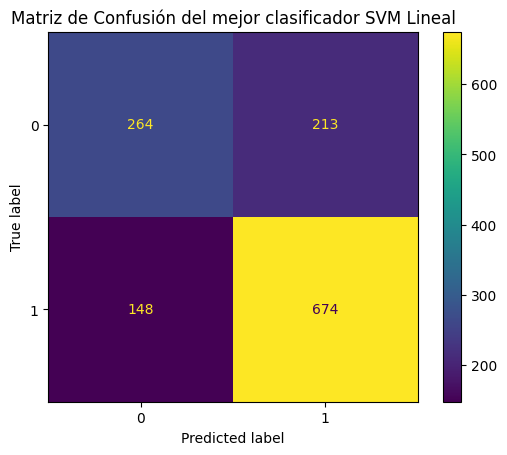

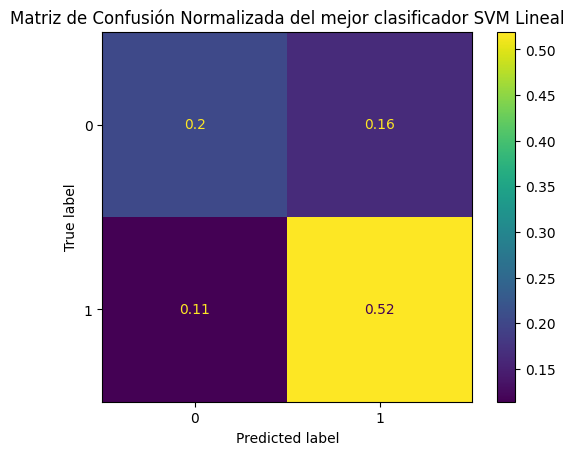

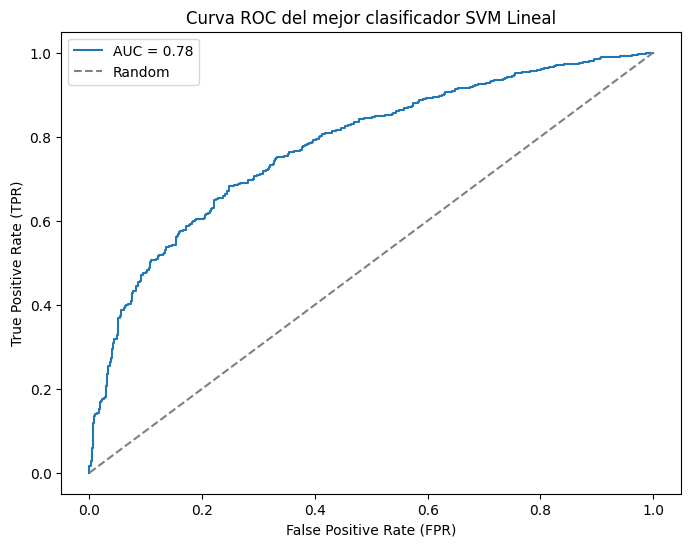

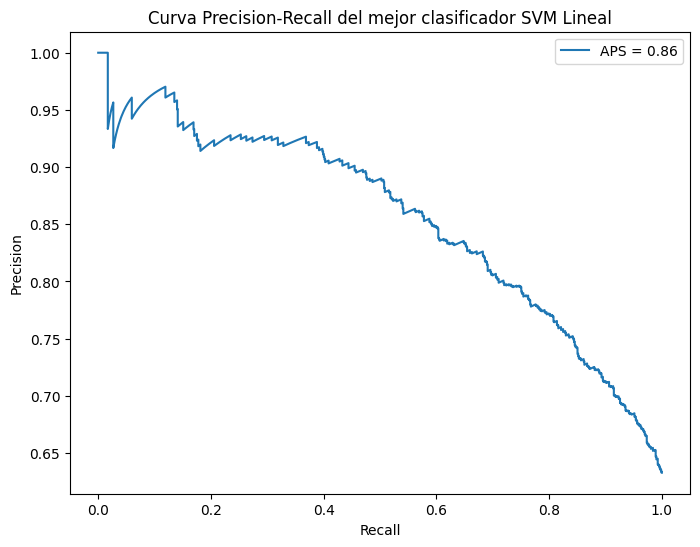

In [ ]:
yPredictedValidation = BestSVML.predict(XValidationNormalized)
Labels=[0, 1]

ConfusionMatrix = confusion_matrix(yValidation, yPredictedValidation, labels=Labels)
Display = ConfusionMatrixDisplay(confusion_matrix=ConfusionMatrix, display_labels=Labels)
Display.plot()
plt.title('Matriz de Confusión del mejor clasificador SVM Lineal')
plt.show()

print('\n')

ConfusionMatrixNormalized = confusion_matrix(yValidation, yPredictedValidation, labels=Labels, normalize='all')
TNNormalized, FPNormalized, FNNormalized, TPNormalized = ConfusionMatrixNormalized.ravel()
DisplayNormalized = ConfusionMatrixDisplay(confusion_matrix=ConfusionMatrixNormalized, display_labels=Labels)
DisplayNormalized.plot()
plt.title('Matriz de Confusión Normalizada del mejor clasificador SVM Lineal')
plt.show()

print('\n')

DecisionFunction = BestSVML.decision_function(XValidationNormalized)

FPR, TPR, Thresholds = roc_curve(yValidation, DecisionFunction)
AUC = auc(FPR, TPR)
plt.figure(figsize=(8, 6))
plt.plot(FPR, TPR, label=f'AUC = {AUC:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Curva ROC del mejor clasificador SVM Lineal')
plt.legend()
plt.show()

print('\n')

Precision, Recall, Threshold = precision_recall_curve(yValidation, DecisionFunction)
AveragePrecisionScore = average_precision_score(yValidation, DecisionFunction)
plt.figure(figsize=(8, 6))
plt.plot(Recall, Precision, label=f'APS = {AveragePrecisionScore:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall del mejor clasificador SVM Lineal')
plt.legend()
plt.show()

## **Support Vector Machine Polinomial**

### Entrenamiento del clasificador

In [ ]:
ParametersGrid = {'C': [0.1, 1, 10], 'degree': [2, 3, 4]}
SVMP = SVC(kernel='poly', coef0=1)
GridSearch = GridSearchCV(estimator=SVMP, param_grid=ParametersGrid, cv=PreDefinedSplit)
InitialTrainingTimePolynomial = time.time()
GridSearch.fit(np.vstack((XTrainNormalized, XValidationNormalized)), np.hstack((yTrain, yValidation)))
FinalTrainingTimePolynomial = time.time()
BestSVMP = GridSearch.best_estimator_
BestSVMP.fit(XTrainNormalized, yTrain)
print(f'El tiempo de entrenamiento es: {FinalTrainingTimePolynomial - InitialTrainingTimePolynomial}')
print(f'El mejor clasificador SVM Polinomial es: SVC(C={BestSVMP.C}, degree={BestSVMP.degree}, coef0={BestSVMP.coef0}, kernel={BestSVMP.kernel})')

El tiempo de entrenamiento es: 114.93021178245544
El mejor clasificador SVM Polinomial es: SVC(C=10, degree=4, coef0=1, kernel=poly)


### Evaluación del mejor clasificador

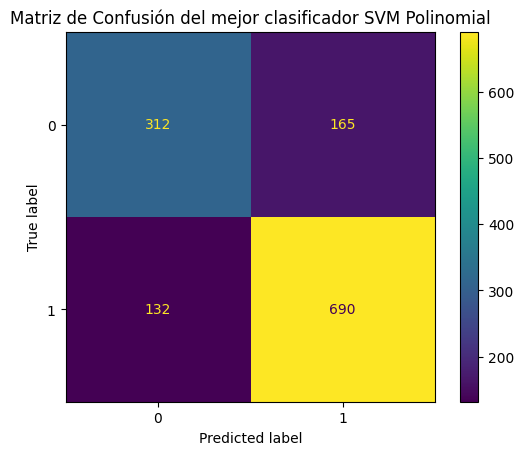

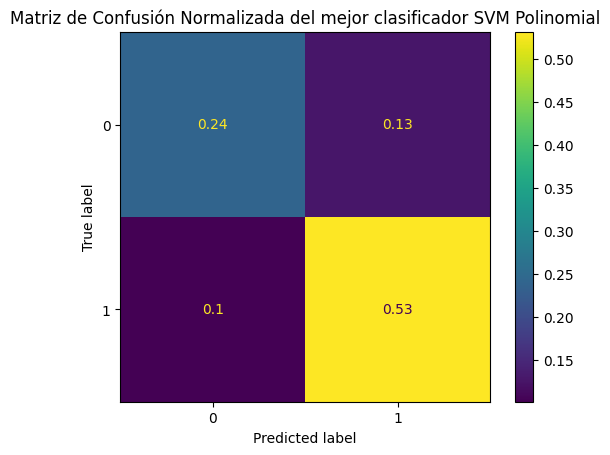

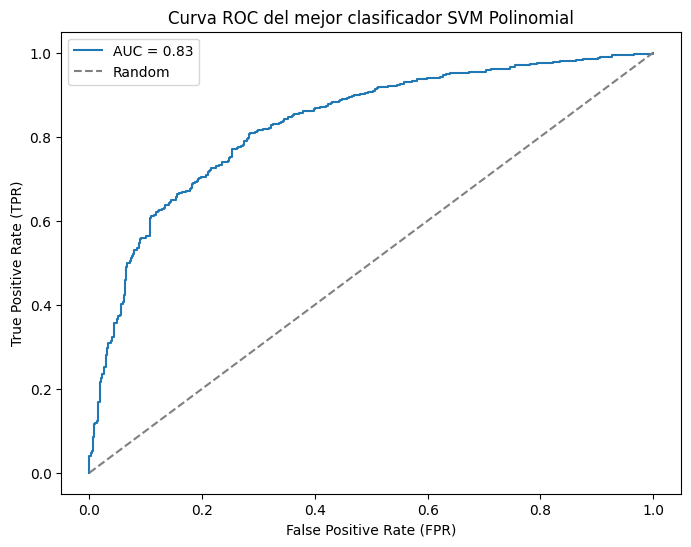

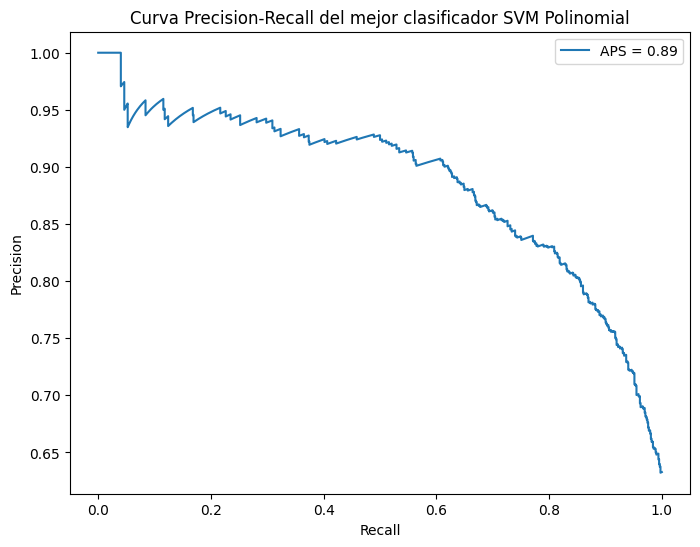

In [ ]:
yPredictedValidation = BestSVMP.predict(XValidationNormalized)
Labels=[0, 1]

ConfusionMatrix = confusion_matrix(yValidation, yPredictedValidation, labels=Labels)
Display = ConfusionMatrixDisplay(confusion_matrix=ConfusionMatrix, display_labels=Labels)
Display.plot()
plt.title('Matriz de Confusión del mejor clasificador SVM Polinomial')
plt.show()

print('\n')

ConfusionMatrixNormalized = confusion_matrix(yValidation, yPredictedValidation, labels=Labels, normalize='all')
TNNormalized, FPNormalized, FNNormalized, TPNormalized = ConfusionMatrixNormalized.ravel()
DisplayNormalized = ConfusionMatrixDisplay(confusion_matrix=ConfusionMatrixNormalized, display_labels=Labels)
DisplayNormalized.plot()
plt.title('Matriz de Confusión Normalizada del mejor clasificador SVM Polinomial')
plt.show()

print('\n')

DecisionFunction = BestSVMP.decision_function(XValidationNormalized)

FPR, TPR, Thresholds = roc_curve(yValidation, DecisionFunction)
AUC = auc(FPR, TPR)
plt.figure(figsize=(8, 6))
plt.plot(FPR, TPR, label=f'AUC = {AUC:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Curva ROC del mejor clasificador SVM Polinomial')
plt.legend()
plt.show()

print('\n')

Precision, Recall, Threshold = precision_recall_curve(yValidation, DecisionFunction)
AveragePrecisionScore = average_precision_score(yValidation, DecisionFunction)
plt.figure(figsize=(8, 6))
plt.plot(Recall, Precision, label=f'APS = {AveragePrecisionScore:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall del mejor clasificador SVM Polinomial')
plt.legend()
plt.show()

## **Support Vector Machine RBF**

### Entrenamiento del clasificador

In [ ]:
ParametersGrid = {'C': [0.01, 0.1, 1, 10, 100], 'gamma': [0.01, 0.1, 1, 10]}
SVMRBF = SVC(kernel='rbf')
GridSearch = GridSearchCV(estimator=SVMRBF, param_grid=ParametersGrid, cv=PreDefinedSplit)
InitialTrainingTimeRBF = time.time()
GridSearch.fit(np.vstack((XTrainNormalized, XValidationNormalized)), np.hstack((yTrain, yValidation)))
FinalTrainingTimeRBF = time.time()
BestSVMRBF = GridSearch.best_estimator_
BestSVMRBF.fit(XTrainNormalized, yTrain)
print(f'El tiempo de entrenamiento es: {FinalTrainingTimeRBF - InitialTrainingTimeRBF}')
print(f'El mejor clasificador SVM Gaussiano es: SVC(C={BestSVMRBF.C}, gamma={BestSVMRBF.gamma}, kernel={BestSVMRBF.kernel})')

El tiempo de entrenamiento es: 22.660074949264526
El mejor clasificador SVM Gaussiano es: SVC(C=10, gamma=10, kernel=rbf)


### Evaluación del mejor clasificador

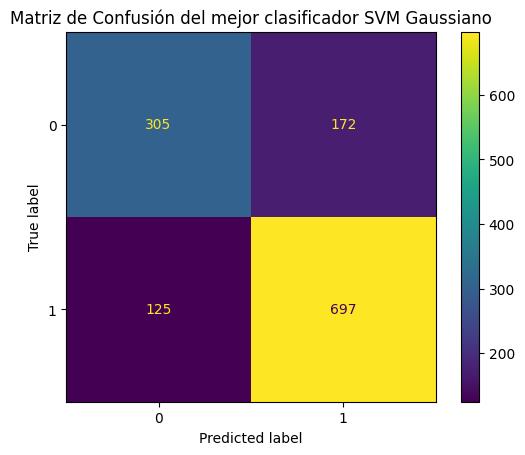

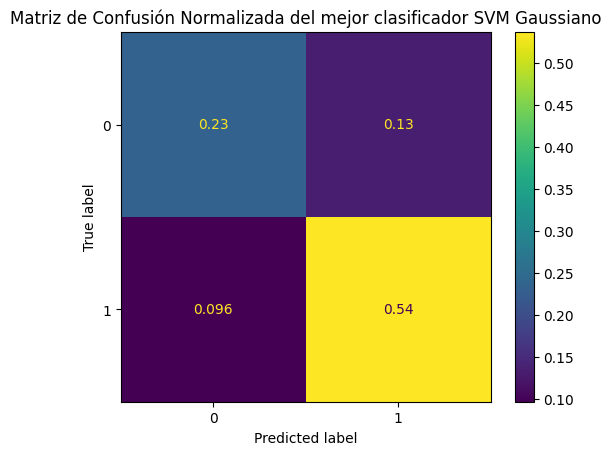

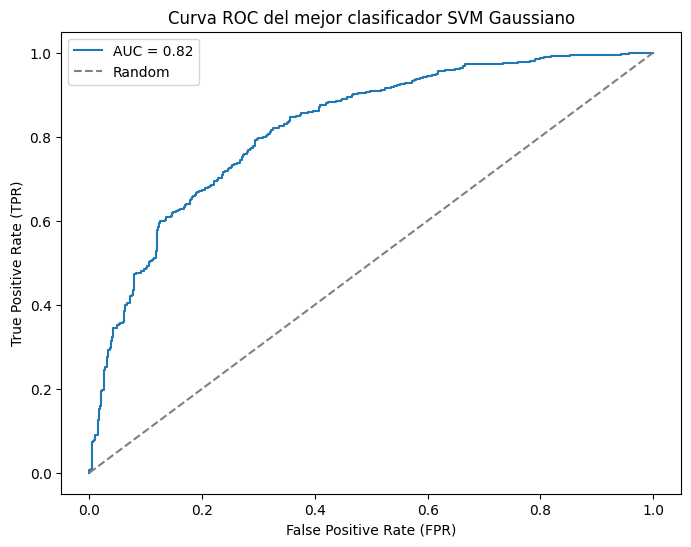

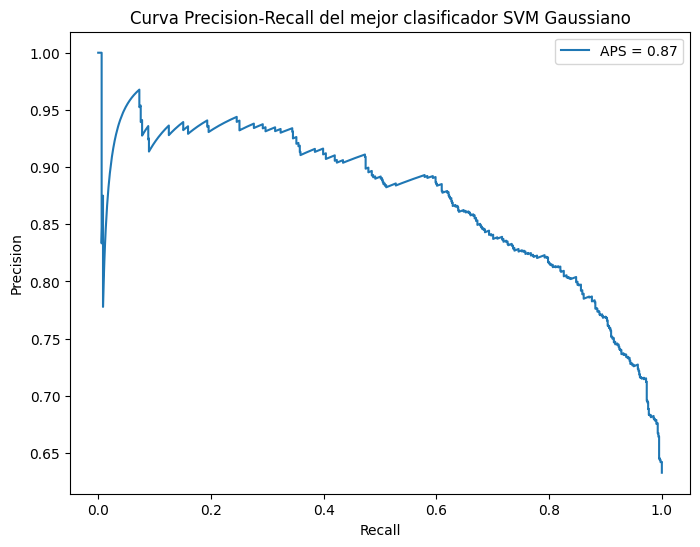

In [ ]:
yPredictedValidation = BestSVMRBF.predict(XValidationNormalized)
Labels=[0, 1]

ConfusionMatrix = confusion_matrix(yValidation, yPredictedValidation, labels=Labels)
Display = ConfusionMatrixDisplay(confusion_matrix=ConfusionMatrix, display_labels=Labels)
Display.plot()
plt.title('Matriz de Confusión del mejor clasificador SVM Gaussiano')
plt.show()

print('\n')

ConfusionMatrixNormalized = confusion_matrix(yValidation, yPredictedValidation, labels=Labels, normalize='all')
TNNormalized, FPNormalized, FNNormalized, TPNormalized = ConfusionMatrixNormalized.ravel()
DisplayNormalized = ConfusionMatrixDisplay(confusion_matrix=ConfusionMatrixNormalized, display_labels=Labels)
DisplayNormalized.plot()
plt.title('Matriz de Confusión Normalizada del mejor clasificador SVM Gaussiano')
plt.show()

print('\n')

DecisionFunction = BestSVMRBF.decision_function(XValidationNormalized)

FPR, TPR, Thresholds = roc_curve(yValidation, DecisionFunction)
AUC = auc(FPR, TPR)
plt.figure(figsize=(8, 6))
plt.plot(FPR, TPR, label=f'AUC = {AUC:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Curva ROC del mejor clasificador SVM Gaussiano')
plt.legend()
plt.show()

print('\n')

Precision, Recall, Threshold = precision_recall_curve(yValidation, DecisionFunction)
AveragePrecisionScore = average_precision_score(yValidation, DecisionFunction)
plt.figure(figsize=(8, 6))
plt.plot(Recall, Precision, label=f'APS = {AveragePrecisionScore:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall del mejor clasificador SVM Gaussiano')
plt.legend()
plt.show()

## **Evaluación y comparación de los mejores clasificadores obtenidos**

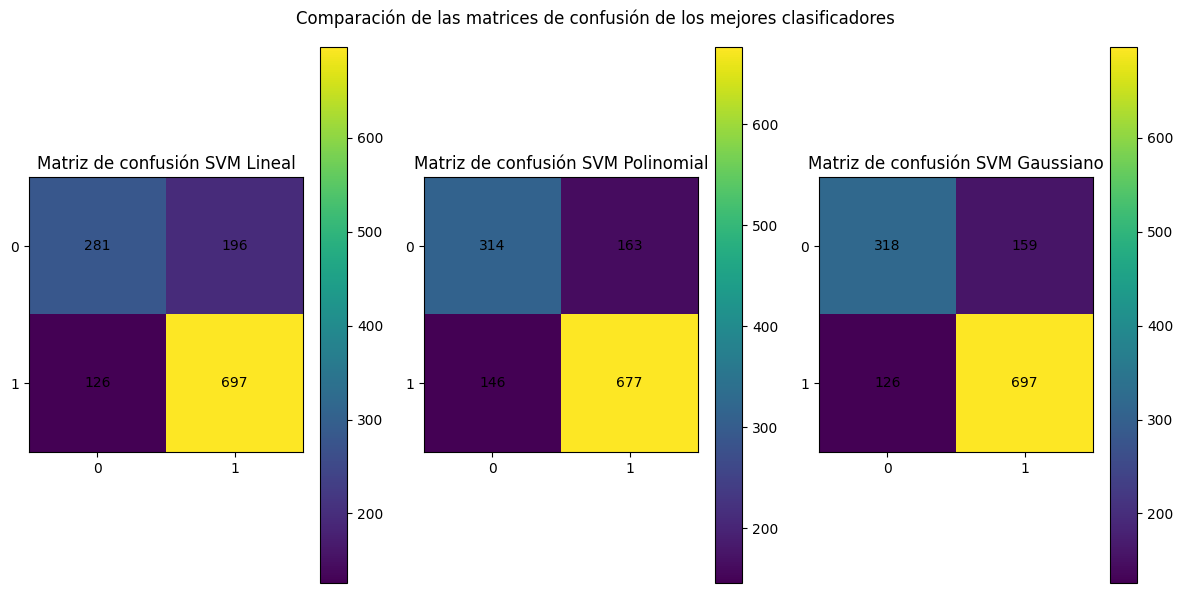

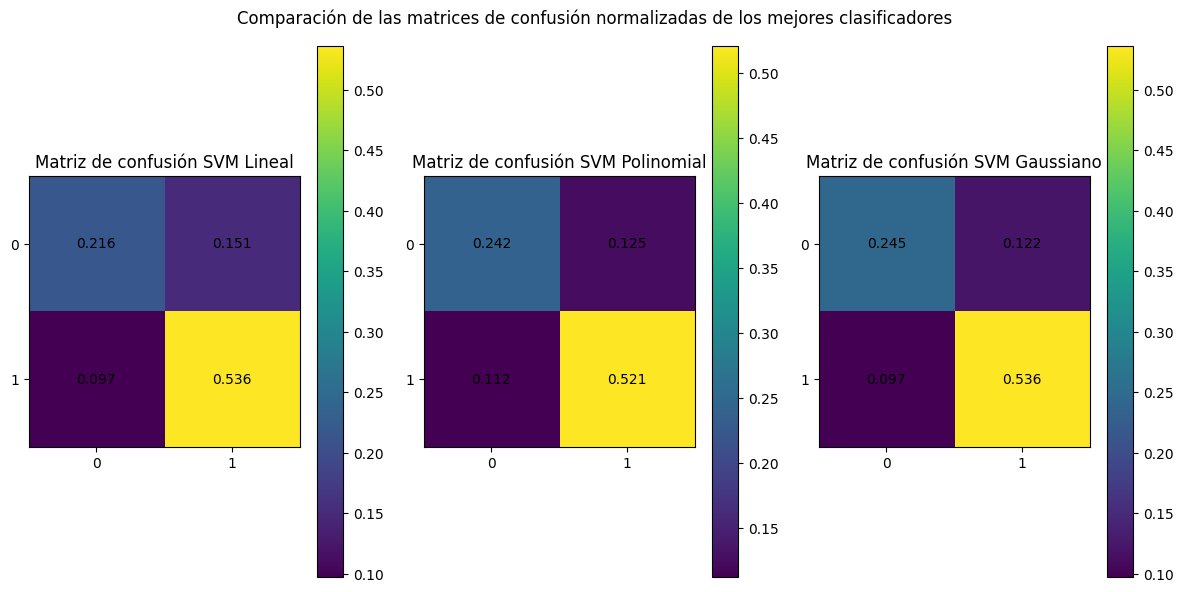

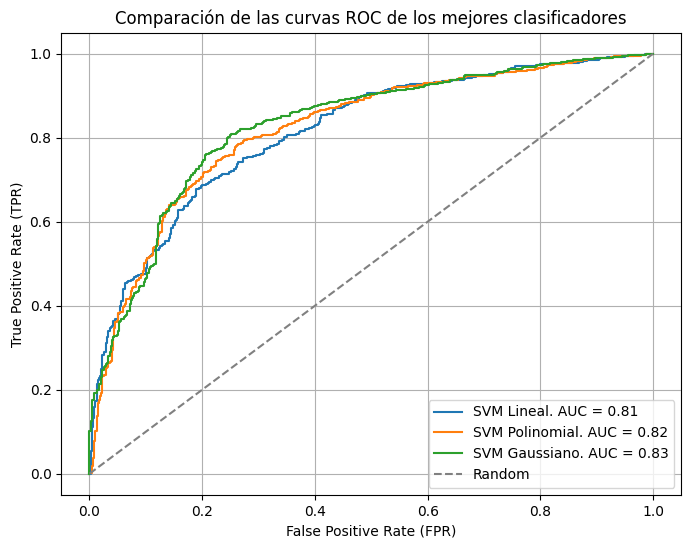

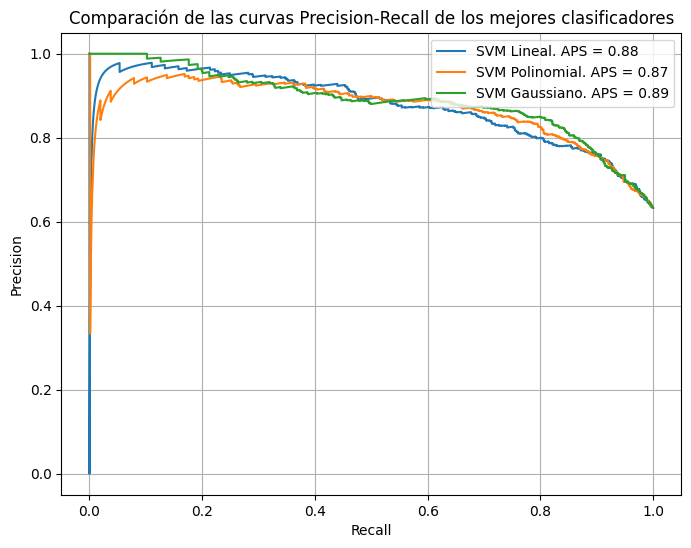

In [ ]:
yPredictedLinear, yPredictedPolynomial, yPredictedRBF = BestSVML.predict(XTestNormalized), BestSVMP.predict(XTestNormalized), BestSVMRBF.predict(XTestNormalized)
Labels = [0, 1]

ConfusionMatrixLinear = confusion_matrix(yTest, yPredictedLinear, labels=Labels)
ConfusionMatrixPolynomial = confusion_matrix(yTest, yPredictedPolynomial, labels=Labels)
ConfusionMatrixRBF = confusion_matrix(yTest, yPredictedRBF, labels=Labels)

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 6))
fig.suptitle('Comparación de las matrices de confusión de los mejores clasificadores')
ILinear = ax1.imshow(ConfusionMatrixLinear, cmap=plt.cm.viridis)
ax1.set_xticks(np.arange(len(Labels)), labels=Labels)
ax1.set_yticks(np.arange(len(Labels)), labels=Labels)
for i in range(len(Labels)):
  for j in range(len(Labels)):
    text = ax1.text(j, i, f'{ConfusionMatrixLinear[i, j]}', ha='center', va='center', color='black')
ax1.set_title('Matriz de confusión SVM Lineal')
fig.colorbar(ILinear, ax=ax1)
IPolynomial = ax2.imshow(ConfusionMatrixPolynomial, cmap=plt.cm.viridis)
ax2.set_xticks(np.arange(len(Labels)), labels=Labels)
ax2.set_yticks(np.arange(len(Labels)), labels=Labels)
for i in range(len(Labels)):
  for j in range(len(Labels)):
    text = ax2.text(j, i, f'{ConfusionMatrixPolynomial[i, j]}', ha='center', va='center', color='black')
ax2.set_title('Matriz de confusión SVM Polinomial')
fig.colorbar(IPolynomial, ax=ax2)
IRBF = ax3.imshow(ConfusionMatrixRBF, cmap=plt.cm.viridis)
ax3.set_xticks(np.arange(len(Labels)), labels=Labels)
ax3.set_yticks(np.arange(len(Labels)), labels=Labels)
for i in range(len(Labels)):
  for j in range(len(Labels)):
    text = ax3.text(j, i, f'{ConfusionMatrixRBF[i, j]}', ha='center', va='center', color='black')
ax3.set_title('Matriz de confusión SVM Gaussiano')
fig.colorbar(IRBF, ax=ax3)
plt.tight_layout()
plt.show()

print('\n')

ConfusionMatrixLinearNormalized = confusion_matrix(yTest, yPredictedLinear, labels=Labels, normalize='all')
ConfusionMatrixPolynomialNormalized = confusion_matrix(yTest, yPredictedPolynomial, labels=Labels, normalize='all')
ConfusionMatrixRBFNormalized = confusion_matrix(yTest, yPredictedRBF, labels=Labels, normalize='all')

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 6))
fig.suptitle('Comparación de las matrices de confusión normalizadas de los mejores clasificadores')
ILinearNormalized = ax1.imshow(ConfusionMatrixLinearNormalized, cmap=plt.cm.viridis)
ax1.set_xticks(np.arange(len(Labels)), labels=Labels)
ax1.set_yticks(np.arange(len(Labels)), labels=Labels)
for i in range(len(Labels)):
  for j in range(len(Labels)):
    text = ax1.text(j, i, f'{ConfusionMatrixLinearNormalized[i, j]:.3f}', ha='center', va='center', color='black')
ax1.set_title('Matriz de confusión SVM Lineal')
fig.colorbar(ILinearNormalized, ax=ax1)
IPolynomialNormalized = ax2.imshow(ConfusionMatrixPolynomialNormalized, cmap=plt.cm.viridis)
ax2.set_xticks(np.arange(len(Labels)), labels=Labels)
ax2.set_yticks(np.arange(len(Labels)), labels=Labels)
for i in range(len(Labels)):
  for j in range(len(Labels)):
    text = ax2.text(j, i, f'{ConfusionMatrixPolynomialNormalized[i, j]:.3f}', ha='center', va='center', color='black')
ax2.set_title('Matriz de confusión SVM Polinomial')
fig.colorbar(IPolynomialNormalized, ax=ax2)
IRBFNormalized = ax3.imshow(ConfusionMatrixRBFNormalized, cmap=plt.cm.viridis)
ax3.set_xticks(np.arange(len(Labels)), labels=Labels)
ax3.set_yticks(np.arange(len(Labels)), labels=Labels)
for i in range(len(Labels)):
  for j in range(len(Labels)):
    text = ax3.text(j, i, f'{ConfusionMatrixRBFNormalized[i, j]:.3f}', ha='center', va='center', color='black')
ax3.set_title('Matriz de confusión SVM Gaussiano')
fig.colorbar(IRBFNormalized, ax=ax3)
plt.tight_layout()
plt.show()

print('\n')

DecisionFunctionLinear, DecisionFunctionPolynomial, DecisionFunctionRBF = BestSVML.decision_function(XTestNormalized), \
                                                                          BestSVMP.decision_function(XTestNormalized), \
                                                                          BestSVMRBF.decision_function(XTestNormalized)
FPRLinear, TPRLinear, ThresholdsLinear = roc_curve(yTest, DecisionFunctionLinear)
AUCLinear = auc(FPRLinear, TPRLinear)
FPRPolynomial, TPRPolynomial, ThresholdsPolynomial = roc_curve(yTest, DecisionFunctionPolynomial)
AUCPolynomial = auc(FPRPolynomial, TPRPolynomial)
FPRRBF, TPRRBF, ThresholdsRBF = roc_curve(yTest, DecisionFunctionRBF)
AUCRBF = auc(FPRRBF, TPRRBF)
plt.figure(figsize=(8, 6))
plt.plot(FPRLinear, TPRLinear, label=f'SVM Lineal. AUC = {AUCLinear:.2f}')
plt.plot(FPRPolynomial, TPRPolynomial, label=f'SVM Polinomial. AUC = {AUCPolynomial:.2f}')
plt.plot(FPRRBF, TPRRBF, label=f'SVM Gaussiano. AUC = {AUCRBF:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Comparación de las curvas ROC de los mejores clasificadores')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print('\n')

PrecisionLinear, RecallLinear, ThresholdLinear = precision_recall_curve(yTest, DecisionFunctionLinear)
AveragePrecisionScoreLinear = average_precision_score(yTest, DecisionFunctionLinear)
PrecisionPolynomial, RecallPolynomial, ThresholdPolynomial = precision_recall_curve(yTest, DecisionFunctionPolynomial)
AveragePrecisionScorePolynomial = average_precision_score(yTest, DecisionFunctionPolynomial)
PrecisionRBF, RecallRBF, ThresholdRBF = precision_recall_curve(yTest, DecisionFunctionRBF)
AveragePrecisionScoreRBF = average_precision_score(yTest, DecisionFunctionRBF)
plt.figure(figsize=(8, 6))
plt.plot(RecallLinear, PrecisionLinear, label=f'SVM Lineal. APS = {AveragePrecisionScoreLinear:.2f}')
plt.plot(RecallPolynomial, PrecisionPolynomial, label=f'SVM Polinomial. APS = {AveragePrecisionScorePolynomial:.2f}')
plt.plot(RecallRBF, PrecisionRBF, label=f'SVM Gaussiano. APS = {AveragePrecisionScoreRBF:.2f}')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Comparación de las curvas Precision-Recall de los mejores clasificadores')
plt.legend(loc='upper right')
plt.grid(True)
plt.show()

## **Análisis de rendimiento de los mejores clasificadores obtenidos**

In [ ]:
TrainingTimes = [FinalTrainingTimeLinear - InitialTrainingTimeLinear, FinalTrainingTimePolynomial - InitialTrainingTimePolynomial, FinalTrainingTimeRBF - InitialTrainingTimeRBF]
AUCValues = [AUCLinear, AUCPolynomial, AUCRBF]
AveragePrecisionScoreValues = [AveragePrecisionScoreLinear, AveragePrecisionScorePolynomial, AveragePrecisionScoreRBF]
TNLinear, FPLinear, FNLinear, TPLinear = ConfusionMatrixLinear.ravel()
TrueLinear, FalseLinear = TNLinear + TPLinear, FPLinear + FNLinear
TNPolynomial, FPPolynomial, FNPolynomial, TPPolynomial = ConfusionMatrixPolynomial.ravel()
TruePolynomial, FalsePolynomial = TNPolynomial + TPPolynomial, FPPolynomial + FNPolynomial
TNRBF, FPRBF, FNRBF, TPRBF = ConfusionMatrixRBF.ravel()
TrueRBF, FalseRBF = TNRBF + TPRBF, FPRBF + FNRBF
Succes = [TrueLinear, TruePolynomial, TrueRBF]
Errors = [FalseLinear, FalsePolynomial, FalseRBF]
TPRValues = [TPRLinear, TPRPolynomial, TPRRBF]
FPRValues = [FPRLinear, FPRPolynomial, FPRRBF]
PrecisionValues = [PrecisionLinear, PrecisionPolynomial, PrecisionRBF]
RecallValues = [RecallLinear, RecallPolynomial, RecallRBF]

def average_metrics(Values):
  AverageValues = []
  for L in Values:
    Average = sum(L) / len(L)
    AverageValues.append(Average)

  return AverageValues

AverageTPRValues = average_metrics(TPRValues)
AveragePrecisionValues = average_metrics(PrecisionValues)

In [ ]:
Metrics = [TrainingTimes, AUCValues, AveragePrecisionScoreValues, Succes, Errors, AverageTPRValues, AveragePrecisionValues]
Weights = [-0.4, 0.3, 0.3, 0.3, -0.1, 0.3, 0.3]
WeightedSums = []
for i in range(len(Metrics[0])):
  IndexSum = sum(Metric[i] * Weight for Metric, Weight in zip(Metrics, Weights[:len(Metrics)]))
  WeightedSums.append(IndexSum)

MaxSum = max(WeightedSums)
MaxIndex = WeightedSums.index(MaxSum)
print(f'Las sumatorias ponderadas son: {WeightedSums}.')
print(f'El máximo de las sumatorias ponderadas es: {MaxSum}.')
if MaxIndex == 0:
  print('El clasificador optimo es el SVM Lineal.')
elif MaxIndex == 1:
  print('El clasificador optimo es el SVM Polinomial.')
elif MaxIndex == 2:
  print('El clasificador optimo es el SVM Gaussiano.')

Las sumatorias ponderadas son: [255.55445993278624, 221.39227455601682, 267.9111340864503].
El máximo de las sumatorias ponderadas es: 267.9111340864503.
El clasificador optimo es el SVM Gaussiano.
